In [25]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize
import os
import re
import skbio
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind, ks_2samp

import testis_model as tm

In [2]:
# Cosine similarity colormap
custom_cmap = LinearSegmentedColormap.from_list(
    'geyser',
    [
        (0.00, '#0B3A35'),
        (0.01, '#37736A'),
        (0.02, '#4B9B92'),
        (0.05, '#75A895'),
        (0.1, '#7BB594'),
        (0.25, '#A3D1A3'),
        (0.4, '#D6E29B'),
        (0.55, '#EAEA9D'),
        (0.7, '#E6DA75'),
        (0.85, '#ECC957'),
        (0.9, '#E8AB51'),
        (0.95, '#DE9C31'),
        (1.0, '#D77229')
    ],
    N=256
)

In [3]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [4]:
# Set sample & fish filters to arrays of values to be used, or "None" to not filter anything.
sample_filter = None
fish_filter = None

none_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

In [5]:
df = pd.read_csv('../experiments/full_pipeline/final_data.csv') 

if sample_filter is not None:
    if isinstance(sample_filter, int):
        sample_filter = [sample_filter]
    df = df[df['sample'].isin(sample_filter)]

if fish_filter is not None:
    if isinstance(fish_filter, str):
        fish_filter = [fish_filter]
    df = df[df['fish'].isin(fish_filter)]
    
print('Samples included:', df['sample'].unique())
print('Fish included:', df['fish'].unique())

Samples included: [ 1  2  5  6  7  8 10 11 12 13 14  4  9 15 16 18 17]
Fish included: <StringArray>
[    'fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8',
 'fishctrl1', 'fishctrl2', 'fishctrl3']
Length: 27, dtype: str


In [6]:
# Remove unedited barcode and fishwater samples
df = df[df["barcode"] != none_barcode]
df = df[~df["fish"].str.contains('fishctrl|fishwater', case=False)]

In [7]:
# Collapse replicates
fish_barcode_counts = (
    df
    .groupby(["fish", "barcode"])["reads"]
    .sum()
    .unstack(fill_value=0)
)

# Reorder fish numerically
fish_barcode_counts = fish_barcode_counts.reindex(
    sorted(fish_barcode_counts.index, key=lambda x: int(re.search(r'\d+$', x).group()))
)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [8]:
# Order fish numerically
def extract_fish_number(name):
    match = re.search(r'(\d+)', name)
    return int(match.group(1)) if match else float("inf")

fish_all = list(fish_barcode_counts.index)

fish_regular = sorted(
    [f for f in fish_all if "fishctrl" not in f.lower()],
    key=extract_fish_number
)

fish_ctrl = sorted(
    [f for f in fish_all if "fishctrl" in f.lower()],
    key=extract_fish_number
)

fish_order = fish_regular + fish_ctrl

fish_barcode_counts = fish_barcode_counts.reindex(fish_order)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [9]:
# Compute cosine similarity between fish
cos_sim_matrix = cosine_similarity(fish_barcode_counts)
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=fish_list, columns=fish_list)
cos_sim_df.head()

,fish1,fish2,fish4,fish5,fish8,fish10,fish12,fish13,fish14,fish15,...,fish26,fish35,fish37,fish38,fish40,fish42,fish44,fish45,fish50,fish51
fish1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
fish2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
fish4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
fish5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
fish8,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# Compute the # of shared barcodes per pair of fish.
shared_counts = np.dot(
    (fish_barcode_counts > 0).astype(int),
    (fish_barcode_counts > 0).astype(int).T
)
shared_df = pd.DataFrame(shared_counts, index=fish_list, columns=fish_list)
shared_df.head()

,fish1,fish2,fish4,fish5,fish8,fish10,fish12,fish13,fish14,fish15,...,fish26,fish35,fish37,fish38,fish40,fish42,fish44,fish45,fish50,fish51
fish1,11,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fish2,0,6,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fish4,0,0,6,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fish5,0,0,0,9,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fish8,0,0,0,0,10,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [21]:
# Helper functions for cosine similarity plots
def prepare_fish_cosine_data(data_df, fish_name, none_barcode=None):
    df_fish = data_df[data_df['fish'] == fish_name].copy()
    if df_fish.empty: return None

    counts = df_fish.groupby(['sample', 'barcode'])['reads'].mean().unstack(fill_value=0)
    if none_barcode and none_barcode in counts.columns: 
        counts = counts.drop(columns=[none_barcode])
        
    def extract_num(x):
        m = re.search(r'(\d+)', str(x))
        return int(m.group(1)) if m else float('inf')
            
    counts = counts.reindex(sorted(counts.index.tolist(), key=extract_num))
    
    res = {
        'sim': pd.DataFrame(cosine_similarity(counts), index=counts.index, columns=counts.index),
        'shared': pd.DataFrame((counts>0).astype(int).dot((counts>0).astype(int).T), index=counts.index, columns=counts.index),
        'diag': (counts>0).astype(int).sum(axis=1),
        'samples': counts.index.tolist()
    }
    return res

def plot_cosine_heatmap(ax, data, sample_map, vmin=0, vmax=1, show_shared=False, show_diag=False):
    mask = np.triu(np.ones_like(data['sim'], dtype=bool), k=1)
    annot = pd.DataFrame('', index=data['samples'], columns=data['samples'])
    if show_shared:
        annot = data['shared'].copy().astype(int)
        if not show_diag: 
            for s in data['samples']: annot.at[s, s] = ''
    elif show_diag:
        for s in data['samples']: annot.at[s, s] = f'{int(data["diag"].loc[s])}'

    sns.heatmap(data['sim'], mask=mask, cmap=custom_cmap, annot=annot, fmt='s', 
                square=True, cbar=False, ax=ax, vmin=vmin, vmax=vmax)
    
    ax.set_xticklabels([str(sample_map.get(int(l.get_text()), l.get_text())) for l in ax.get_xticklabels()], fontname='Arial Narrow')
    ax.set_yticklabels([str(sample_map.get(int(l.get_text()), l.get_text())) for l in ax.get_yticklabels()], rotation=0, fontname='Arial Narrow')
    
    ax.set_xlabel('')
    ax.set_ylabel('')

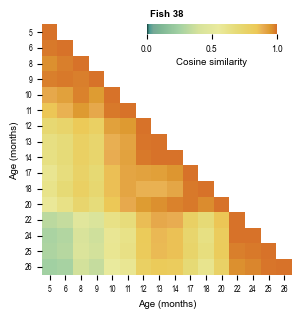

In [22]:
fish_name = 'fish38'
data = prepare_fish_cosine_data(df, fish_name)

fig, ax = plt.subplots(figsize=(3.25, 3.25))
plot_cosine_heatmap(ax, data, tm.data_processing.sample_map_int)

ax.set_title(f'Fish {fish_name[4:]}', fontweight='bold')
ax.set_xlabel('Age (months)'); ax.set_ylabel('Age (months)')

cax = fig.add_axes([0.45, 0.85, 0.4, 0.03]) 
cbar = ColorbarBase(cax, cmap=custom_cmap, norm=Normalize(0, 1), orientation='horizontal')
cbar.outline.set_visible(False); cbar.ax.tick_params(labelsize=6)
cbar.set_ticks([0, 0.5, 1]); cbar.set_ticklabels(['0.0', '0.5', '1.0'])
cbar.set_label('Cosine similarity', labelpad=3)

plt.savefig(f'images/cosines/{fish_name}_cosine.svg', bbox_inches='tight', transparent=True)
plt.savefig(f'images/cosines/{fish_name}_cosine.png', dpi=300, bbox_inches='tight', transparent=True)

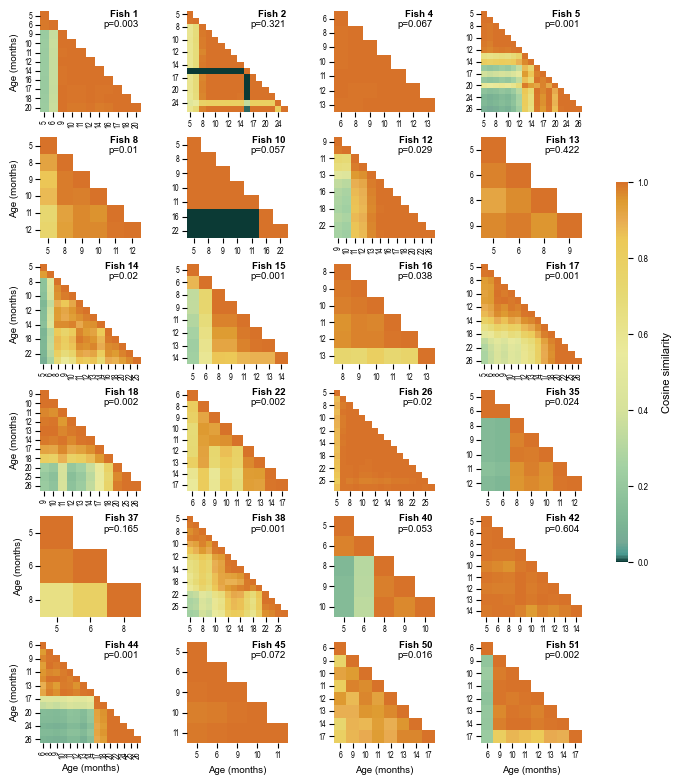

In [23]:
show_shared_sample_counts = False
show_diagonal_counts = False
fish_list = ['fish1', 'fish2', 'fish4', 'fish5', 'fish8', 'fish10', 'fish12', 'fish13',
             'fish14', 'fish15', 'fish16', 'fish17', 'fish18', 'fish22', 'fish26', 'fish35',
             'fish37', 'fish38', 'fish40', 'fish42', 'fish44', 'fish45', 'fish50', 'fish51']
sample_map = tm.data_processing.sample_map_int

n_cols, n_rows = 4, 6
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.5, 9.5))
plt.subplots_adjust(hspace=0.25, wspace=0.05)
axes = axes.flatten()

fish_data_cache, all_sim_values = {}, []

# Process and compute Mantel tests
for fish_name in fish_list:
    res = prepare_fish_cosine_data(df, fish_name, none_barcode)
    if not res: continue
    
    dm = 1 - res['sim'].values
    np.fill_diagonal(dm, 0)
    times = np.array([sample_map[s] for s in res['samples']])
    dist_time = np.abs(times[:, None] - times[None, :])
    coef, p, n = skbio.stats.distance.mantel(dm, dist_time, alternative='greater')
    
    res['p_val'] = p
    fish_data_cache[fish_name] = res
    all_sim_values.extend(res['sim'].values[~np.triu(np.ones_like(res['sim'], dtype=bool), k=1)])

vmin_g, vmax_g = min(all_sim_values), max(all_sim_values)
for idx, fish_name in enumerate(fish_list):
    ax = axes[idx]
    if fish_name not in fish_data_cache:
        ax.axis('off')
        continue
        
    data = fish_data_cache[fish_name]
    plot_cosine_heatmap(ax, data, sample_map, vmin=vmin_g, vmax=vmax_g)
    
    # Styling
    fish_num = ''.join(filter(str.isdigit, fish_name))
    ax.text(0.98, 0.95, f'Fish {fish_num}', transform=ax.transAxes, ha='right', fontweight='bold', fontsize=7)
    ax.text(0.98, 0.85, f'p={data["p_val"]:.3g}', transform=ax.transAxes, ha='right', fontsize=7)
    
    ax.tick_params(axis='both', labelsize=6, pad=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname('Arial Narrow')
    
    if idx % 4 == 0: ax.set_ylabel('Age (months)', fontsize=7)
    else: ax.set_ylabel('')

    if idx >= 20: ax.set_xlabel('Age (months)', fontsize=7)
    else: ax.set_xlabel('')

# Hide any extra empty subplots
for i in range(len(fish_list), len(axes)):
    axes[i].axis('off')

# Colorbar
cax = fig.add_axes([0.92, 0.3, 0.015, 0.4])
cbar = ColorbarBase(cax, cmap=custom_cmap, norm=Normalize(vmin=vmin_g, vmax=vmax_g))
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=7)
for label in cbar.ax.get_yticklabels():
    label.set_fontname('Arial Narrow')
cbar.set_label('Cosine similarity', fontsize=8, labelpad=10)


plt.savefig(f'images/cosines/facet_cosine.svg', bbox_inches='tight', transparent=True)
plt.savefig(f'images/cosines/facet_cosine.png', dpi=300, bbox_inches='tight', transparent=True)

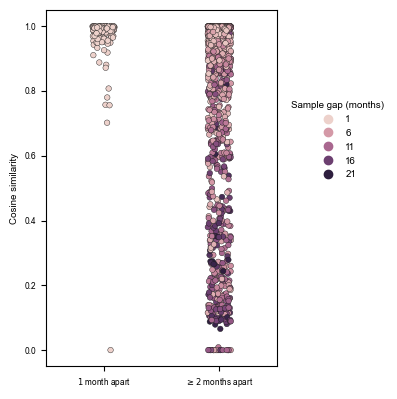

In [38]:
meta_rows = []
for fish, d in fish_data_cache.items():
    sim_matrix, samples = d['sim'].values, d['samples']
    for i in range(len(samples)):
        for j in range(i):
            dist = abs(sample_map[samples[i]] - sample_map[samples[j]])
            meta_rows.append({
                'similarity': sim_matrix[i, j],
                'distance': dist,
                'category': '$1$ month apart' if dist == 1 else '$\\geq 2$ months apart'
            })

cosine_df = pd.DataFrame(meta_rows)

norm = plt.Normalize(cosine_df['distance'].min(), cosine_df['distance'].max())
cmap = sns.cubehelix_palette(as_cmap=True)

plt.figure(figsize=(4, 4))
ax = sns.stripplot(
    data=cosine_df, x='category', y='similarity', hue='distance',
    palette=cmap, size=4, dodge=False, linewidth=0.3,
    order=['$1$ month apart', '$\\geq 2$ months apart']
)

# Styling
ax.set_xlabel('')
ax.set_ylabel('Cosine similarity')
ax.tick_params(axis='both')

# Legend
ax.legend_.remove()
legend_distances = [1, 6, 11, 16, 21]
handles = [plt.Line2D([0], [0], marker='o', linestyle='', markersize=6, 
                       color=cmap(norm(d))) for d in legend_distances]

ax.legend(handles, [str(d) for d in legend_distances], 
          title='Sample gap (months)', loc='lower left', bbox_to_anchor=(1.02, 0.5),
          frameon=False, fontsize=7, title_fontsize=7)

plt.tight_layout()
plt.savefig('images/cosines/aggregate_cosine.svg', bbox_inches='tight')
plt.savefig('images/cosines/aggregate_cosine.png', dpi = 300, bbox_inches='tight')
plt.show()